<a href="https://colab.research.google.com/github/jano87/diplomado-MLunsupervised/blob/main/Perfiles_Ocultos_con_PCA_KMEANS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentación de clientes de tarjetas de crédito mediante PCA y K-Means
# Descripción general

Este proyecto analiza un conjunto de datos de clientes de tarjetas de crédito utilizando dos enfoques de agrupación: K-Means sobre el conjunto completo de características preprocesadas y K-Means tras una reducción de dimensionalidad basada en PCA. El objetivo es comparar si el PCA preserva la estructura principal de agrupación a la vez que mejora la separación entre los grupos.

El flujo de trabajo consta de análisis exploratorio de datos (EDA), preprocesamiento, agrupación K-Means con todas las características, agrupación K-Means basada en PCA y evaluación del modelo mediante el índice ARI y la puntuación de silueta (Silhouette Score).

Dado que muchas variables numéricas presentan un sesgo hacia la derecha, los valores faltantes se imputaron utilizando la mediana en lugar de la media.

Se omitió la eliminación de valores atípicos porque los valores extremos en columnas con sesgo a la derecha pueden representar a usuarios intensivos relevantes.

El flujo de trabajo general es:

1. Cargar el conjunto de datos de clientes de tarjetas de crédito.
2. Explorar valores faltantes, duplicados, distribuciones y valores atípicos.
3. Aplicar imputación por la mediana, transformación log1p y escalado estándar.
4. Realizar agrupamiento K-Means sobre el conjunto completo de características.
5. Aplicar PCA y realizar agrupamiento K-Means sobre el espacio de características reducido.
6. Comparar ambos resultados de agrupamiento utilizando el índice ARI, la puntuación de silueta (Silhouette Score) y mapas de calor de perfiles de clúster.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import math

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import missingno as msno

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import silhouette_score

import plotly.express as px
import nbformat


In [ ]:
local_path = "/content/Dataset_CreditCard.csv"

data = pd.read_csv(local_path, encoding='latin1')
data.head()

,ID_CLTE,SALDO,FRECUENCIA_DEL_SALDO,COMPRAS,COMPRAS_EN_UN_SOLO_PAGO,COMPRAS_A_PLAZOS,ADELANTO_DE_EFECTIVO,FRECUENCIA_DE_COMPRAS,FRECUENCIA_DE_COMPRAS_EN_UN_SOLO_PAGO,FRECUENCIA_DE_COMPRAS_A_PLAZOS,FRECUENCIA_DE_ADELANTOS_DE_EFECTIVO,TRANSACCIONES_DE_ADELANTO_DE_EFECTIVO,TRANSACCIONES_DE_COMPRA,LÍMITE_DE_CRÉDITO,PAGOS,PAGOS_MÍNIMOS,PORCENTAJE_DE_PAGO_TOTAL,ANTIGÜEDAD
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


# EDA

In [ ]:
df = data.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   ID_CLTE                                8950 non-null   object 
 1   SALDO                                  8950 non-null   float64
 2   FRECUENCIA_DEL_SALDO                   8950 non-null   float64
 3   COMPRAS                                8950 non-null   float64
 4   COMPRAS_EN_UN_SOLO_PAGO                8950 non-null   float64
 5   COMPRAS_A_PLAZOS                       8950 non-null   float64
 6   ADELANTO_DE_EFECTIVO                   8950 non-null   float64
 7   FRECUENCIA_DE_COMPRAS                  8950 non-null   float64
 8   FRECUENCIA_DE_COMPRAS_EN_UN_SOLO_PAGO  8950 non-null   float64
 9   FRECUENCIA_DE_COMPRAS_A_PLAZOS         8950 non-null   float64
 10  FRECUENCIA_DE_ADELANTOS_DE_EFECTIVO    8950 non-null   float64
 11  TRAN

In [ ]:
# comprobar valores faltantes
df.isna().sum()

,0
ID_CLTE,0
SALDO,0
FRECUENCIA_DEL_SALDO,0
COMPRAS,0
COMPRAS_EN_UN_SOLO_PAGO,0
COMPRAS_A_PLAZOS,0
ADELANTO_DE_EFECTIVO,0
FRECUENCIA_DE_COMPRAS,0
FRECUENCIA_DE_COMPRAS_EN_UN_SOLO_PAGO,0
FRECUENCIA_DE_COMPRAS_A_PLAZOS,0


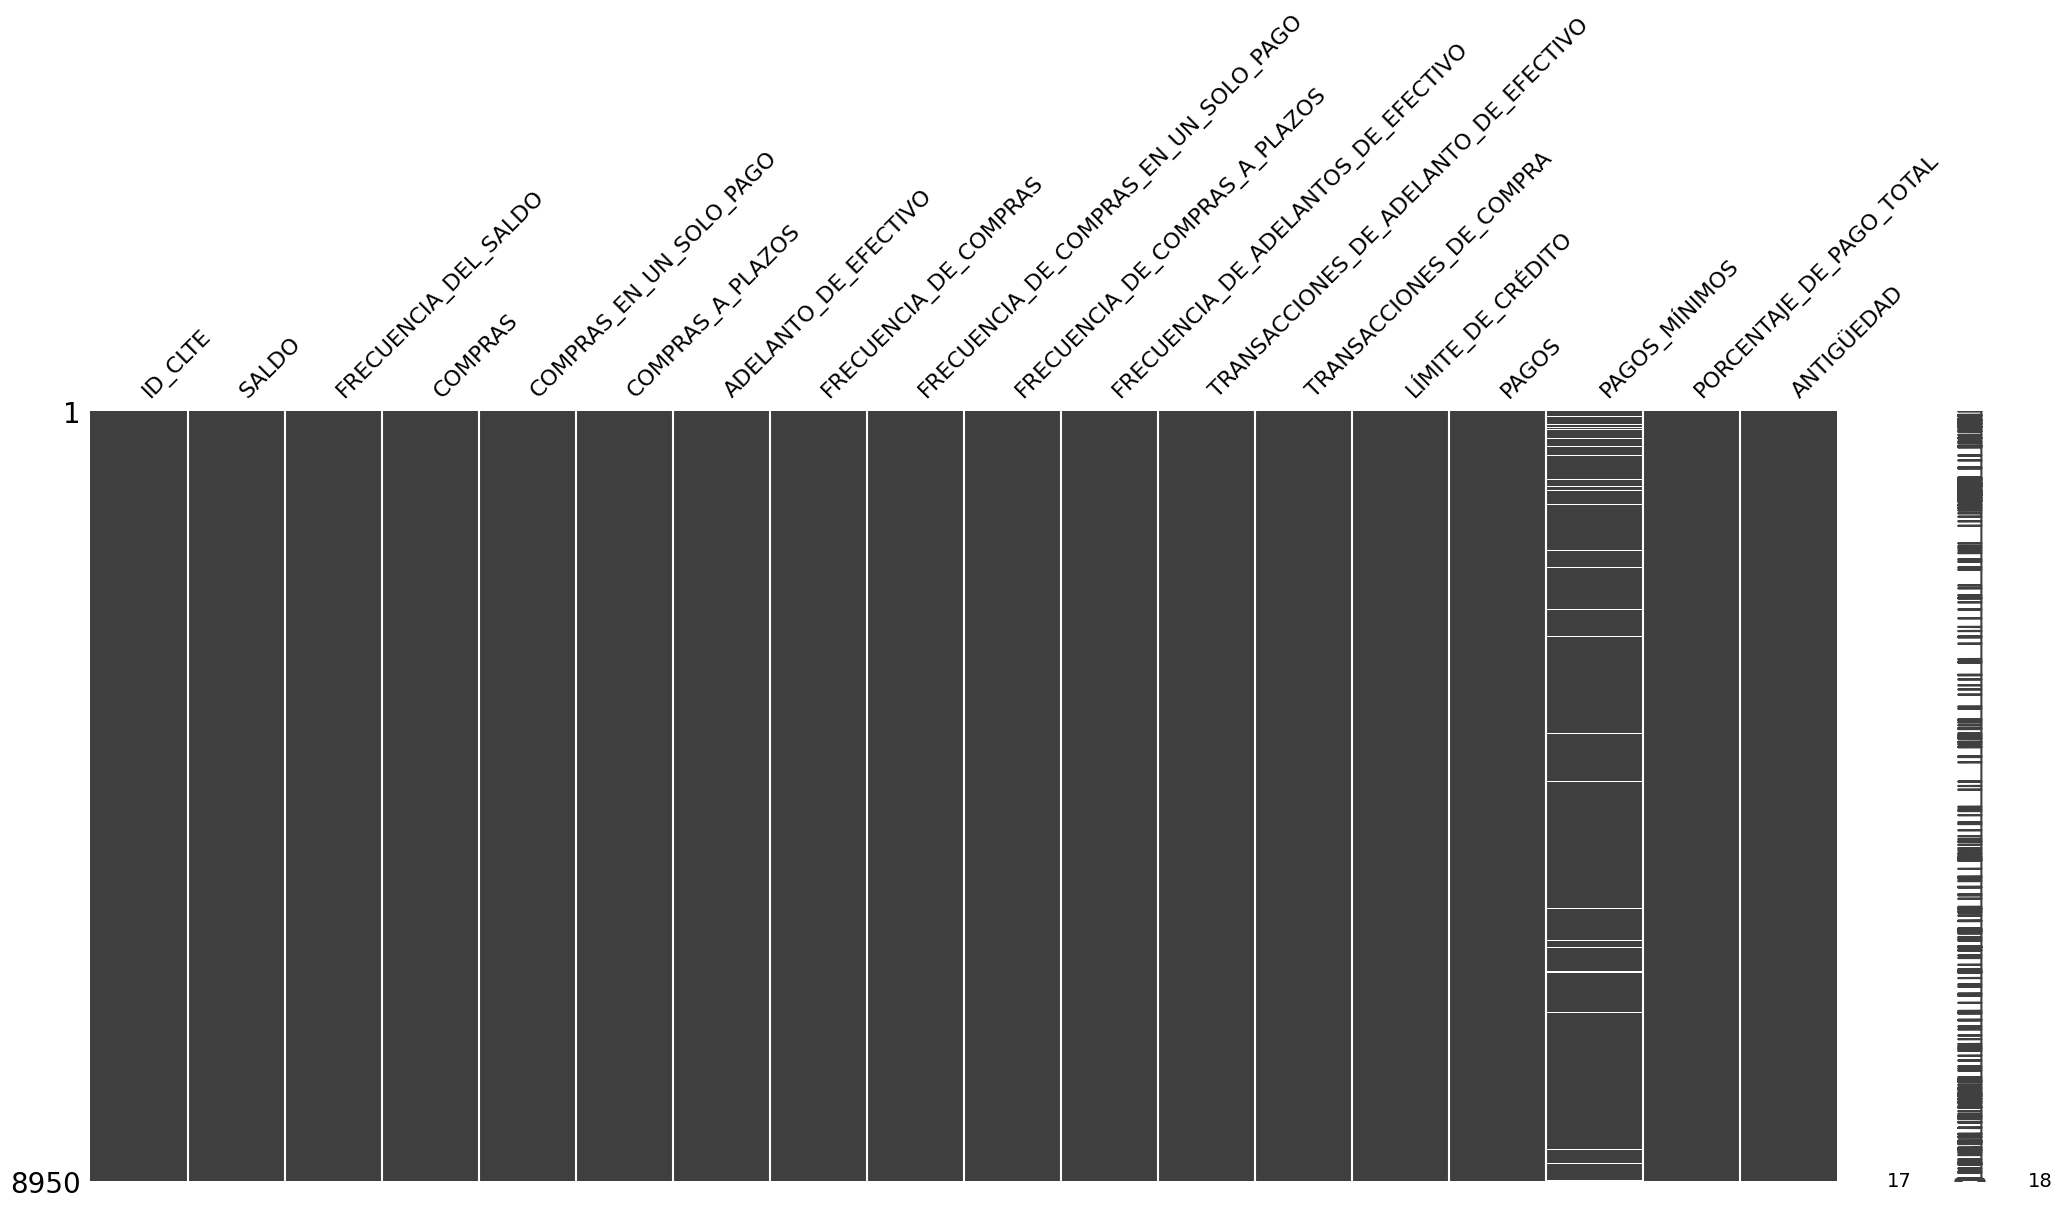

In [ ]:
# visualize missing values
msno.matrix(df)
plt.show()

In [ ]:
# check duplicates
df.duplicated().sum()

# df.drop_duplicates()

np.int64(0)

In [ ]:
# check statistic
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SALDO,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
FRECUENCIA_DEL_SALDO,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
COMPRAS,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
COMPRAS_EN_UN_SOLO_PAGO,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
COMPRAS_A_PLAZOS,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
ADELANTO_DE_EFECTIVO,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
FRECUENCIA_DE_COMPRAS,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
FRECUENCIA_DE_COMPRAS_EN_UN_SOLO_PAGO,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
FRECUENCIA_DE_COMPRAS_A_PLAZOS,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
FRECUENCIA_DE_ADELANTOS_DE_EFECTIVO,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


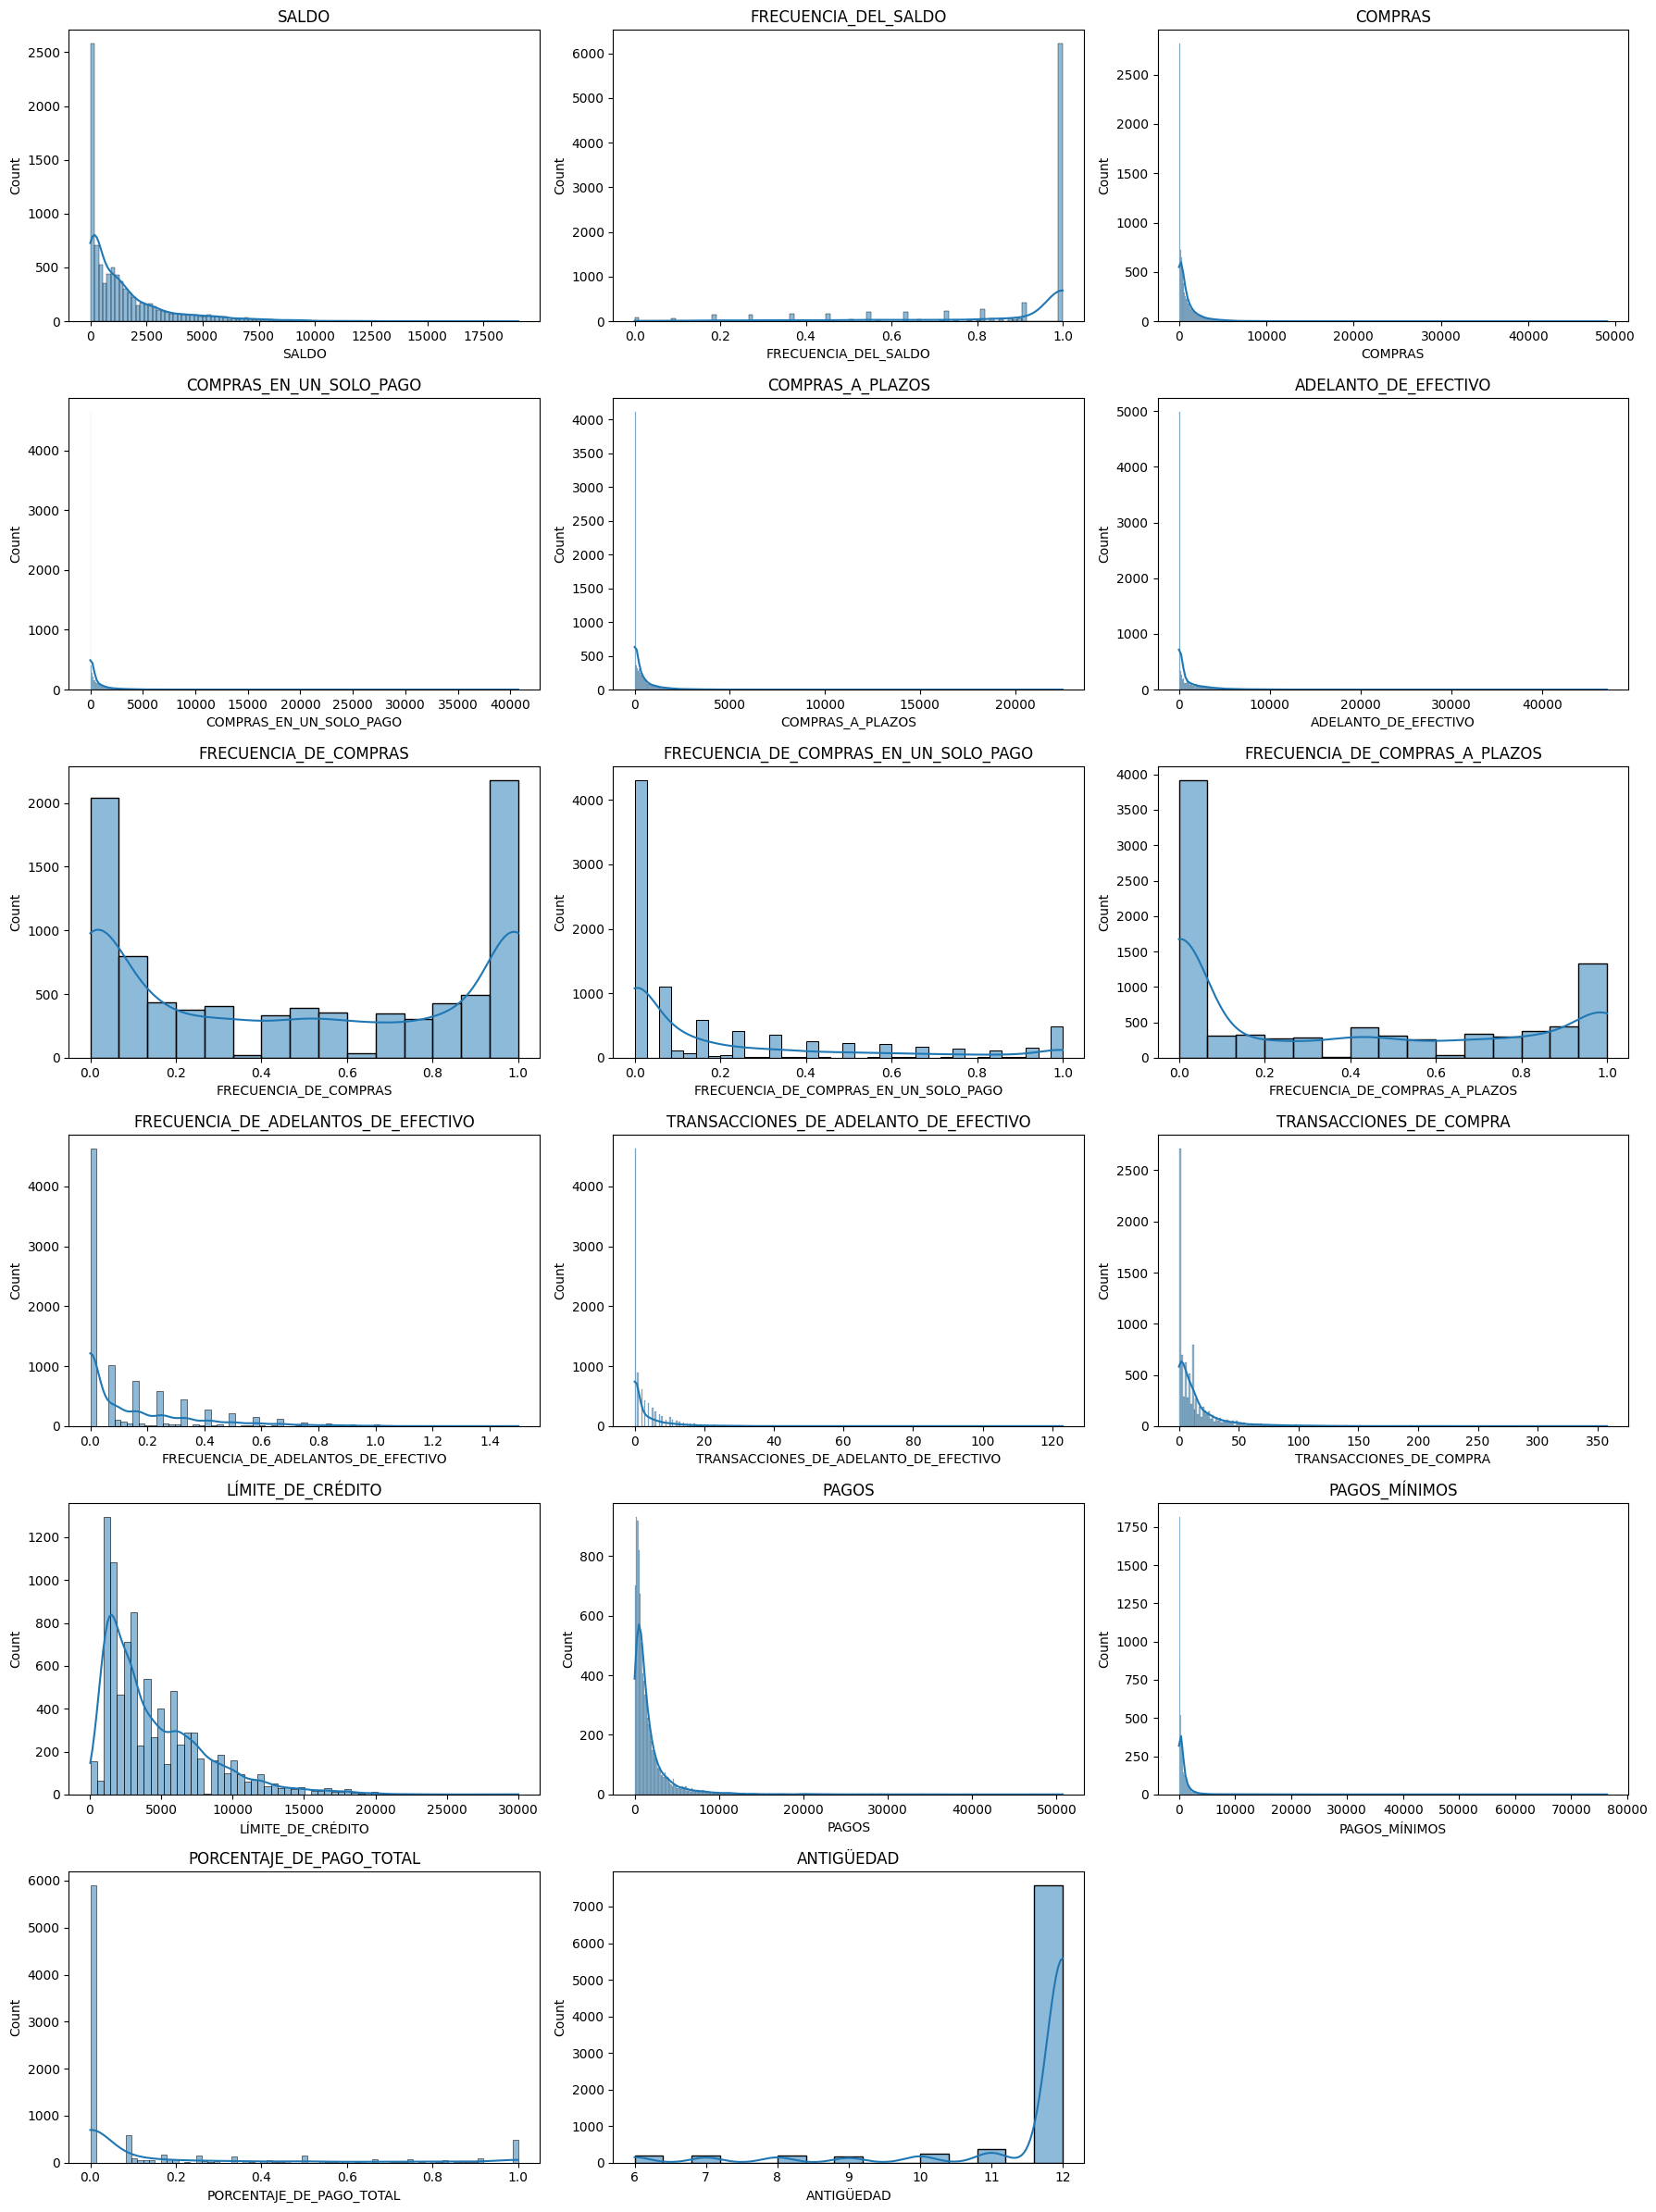

In [ ]:
# histogram visualization
numeric_cols = df.select_dtypes(include='number').columns

n_cols = 3
n_rows = math.ceil(len(numeric_cols)/n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize = (18, 4*n_rows))
axes = axes.flatten()

for i,col in enumerate(numeric_cols):
    sns.histplot(data = df, x = col, ax = axes[i], kde = True)
    axes[i].set_title(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
#verificar los valores de antigüedad

df['ANTIGÜEDAD'].value_counts()

,count
ANTIGÜEDAD,
12,7584
11,365
10,236
6,204
8,196
7,190
9,175


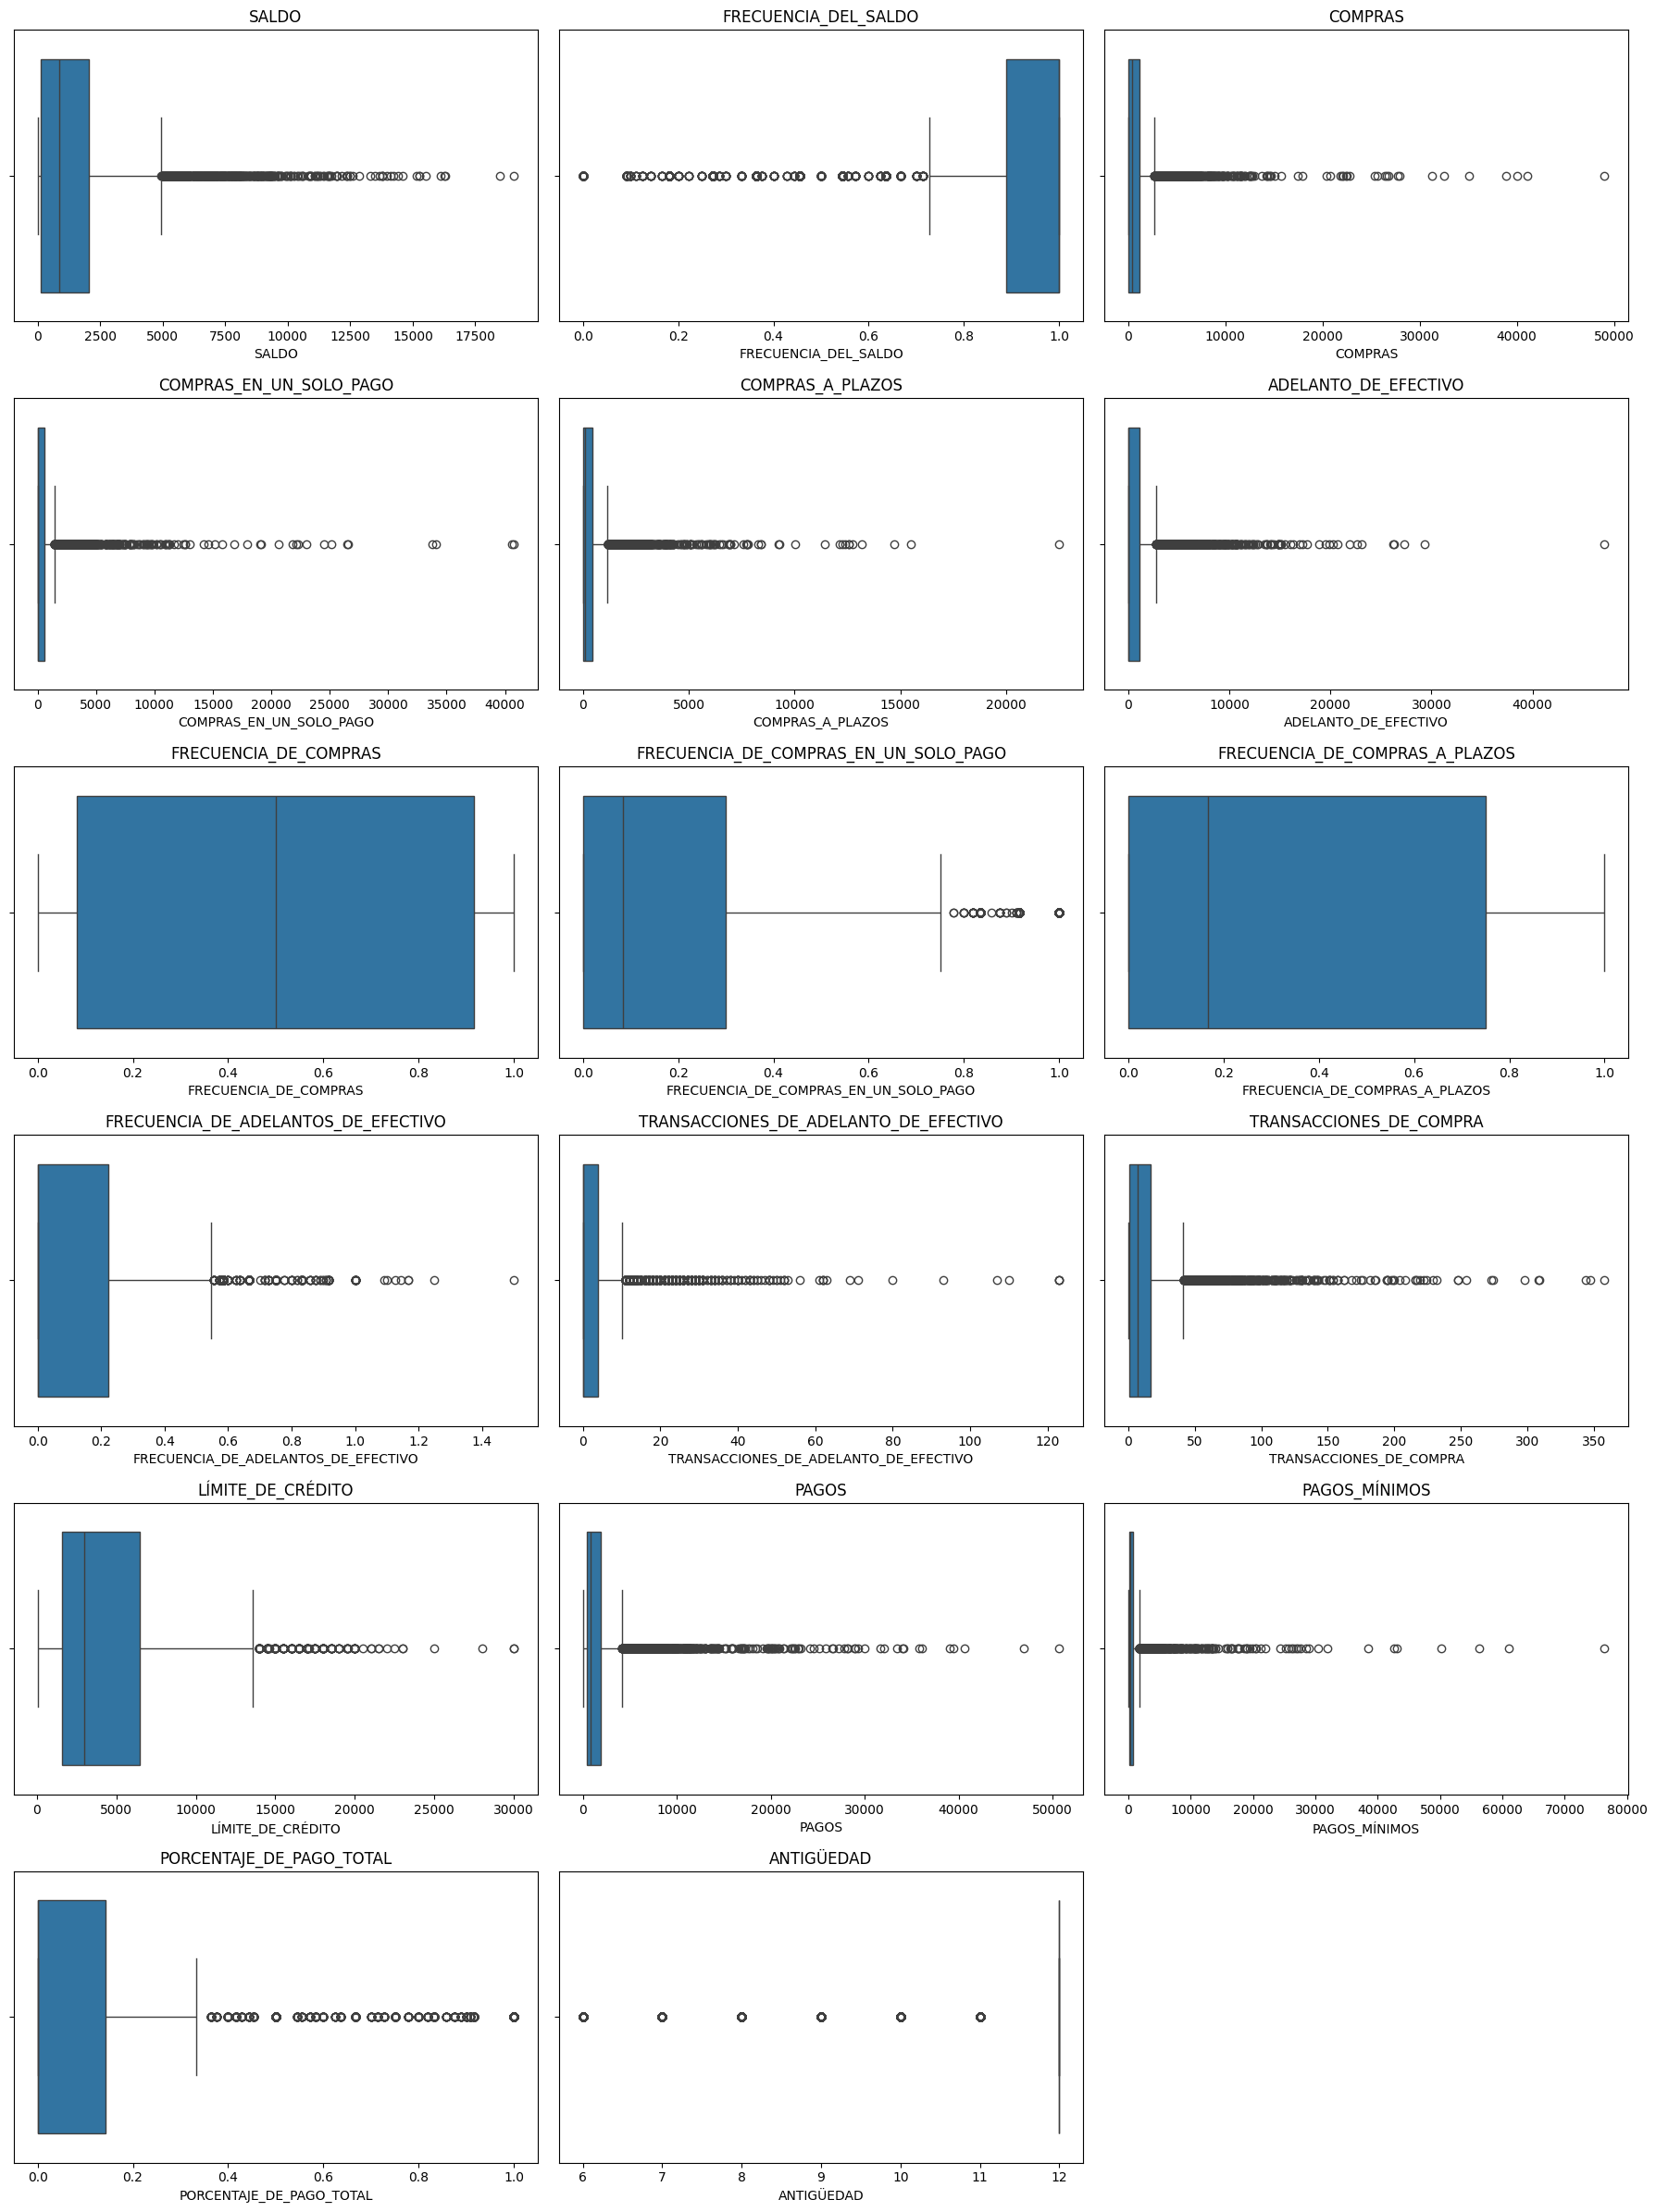

In [ ]:
# boxplot visualization
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Las visualizaciones muestran que muchas variables numéricas presentan un fuerte sesgo hacia la derecha.

Para reducir la asimetría y mejorar el rendimiento de la agrupación, podemos aplicar una transformación log1p antes del escalado y la agrupación.

# Preprocesamiento

In [ ]:
# Imputación
# Este conjunto de datos presenta valores faltantes únicamente en las columnas numéricas.
# Por lo tanto, no se requiere imputación para variables categóricas.

def fill_numeric_missing_values(df, id_col="ID_CLTE"):
    result = df.copy()

    numeric_cols = (
        result.drop(columns=id_col, errors="ignore")
        .select_dtypes(include="number")
        .columns
    )

    # Para la imputación, la mediana es más adecuada que la media.
    # porque muchas columnas numéricas presentan un sesgo hacia la derecha.
    result[numeric_cols] = result[numeric_cols].fillna(result[numeric_cols].median())
    return result

df_imputed = fill_numeric_missing_values(df)

In [ ]:
# Transformación Logarítmica

# definir las columnas que se van a transformar
log_cols = [
    "SALDO",
    "COMPRAS",
    "COMPRAS_EN_UN_SOLO_PAGO",
    "COMPRAS_A_PLAZOS",
    "ADELANTO_DE_EFECTIVO",
    "TRANSACCIONES_DE_ADELANTO_DE_EFECTIVO",
    "TRANSACCIONES_DE_COMPRA",
    "LÍMITE_DE_CRÉDITO",
    "PAGOS",
    "PAGOS_MÍNIMOS",
]

def apply_log1p(df, cols):
    result = df.copy()
    result[cols] = np.log1p(result[cols])
    return result

df_log = apply_log1p(df_imputed, log_cols)

# Nota: La transformación logarítmica se utiliza exclusivamente para mejorar la separación de los clústeres y el rendimiento del modelo.
# Para extraer información empresarial interpretable, añade las etiquetas de clúster resultantes a los datos originales.

En este proyecto, los valores extremos pueden representar un comportamiento significativo de los clientes.

Por lo tanto, se omitió la eliminación de valores atípicos para evitar perder segmentos de clientes importantes.

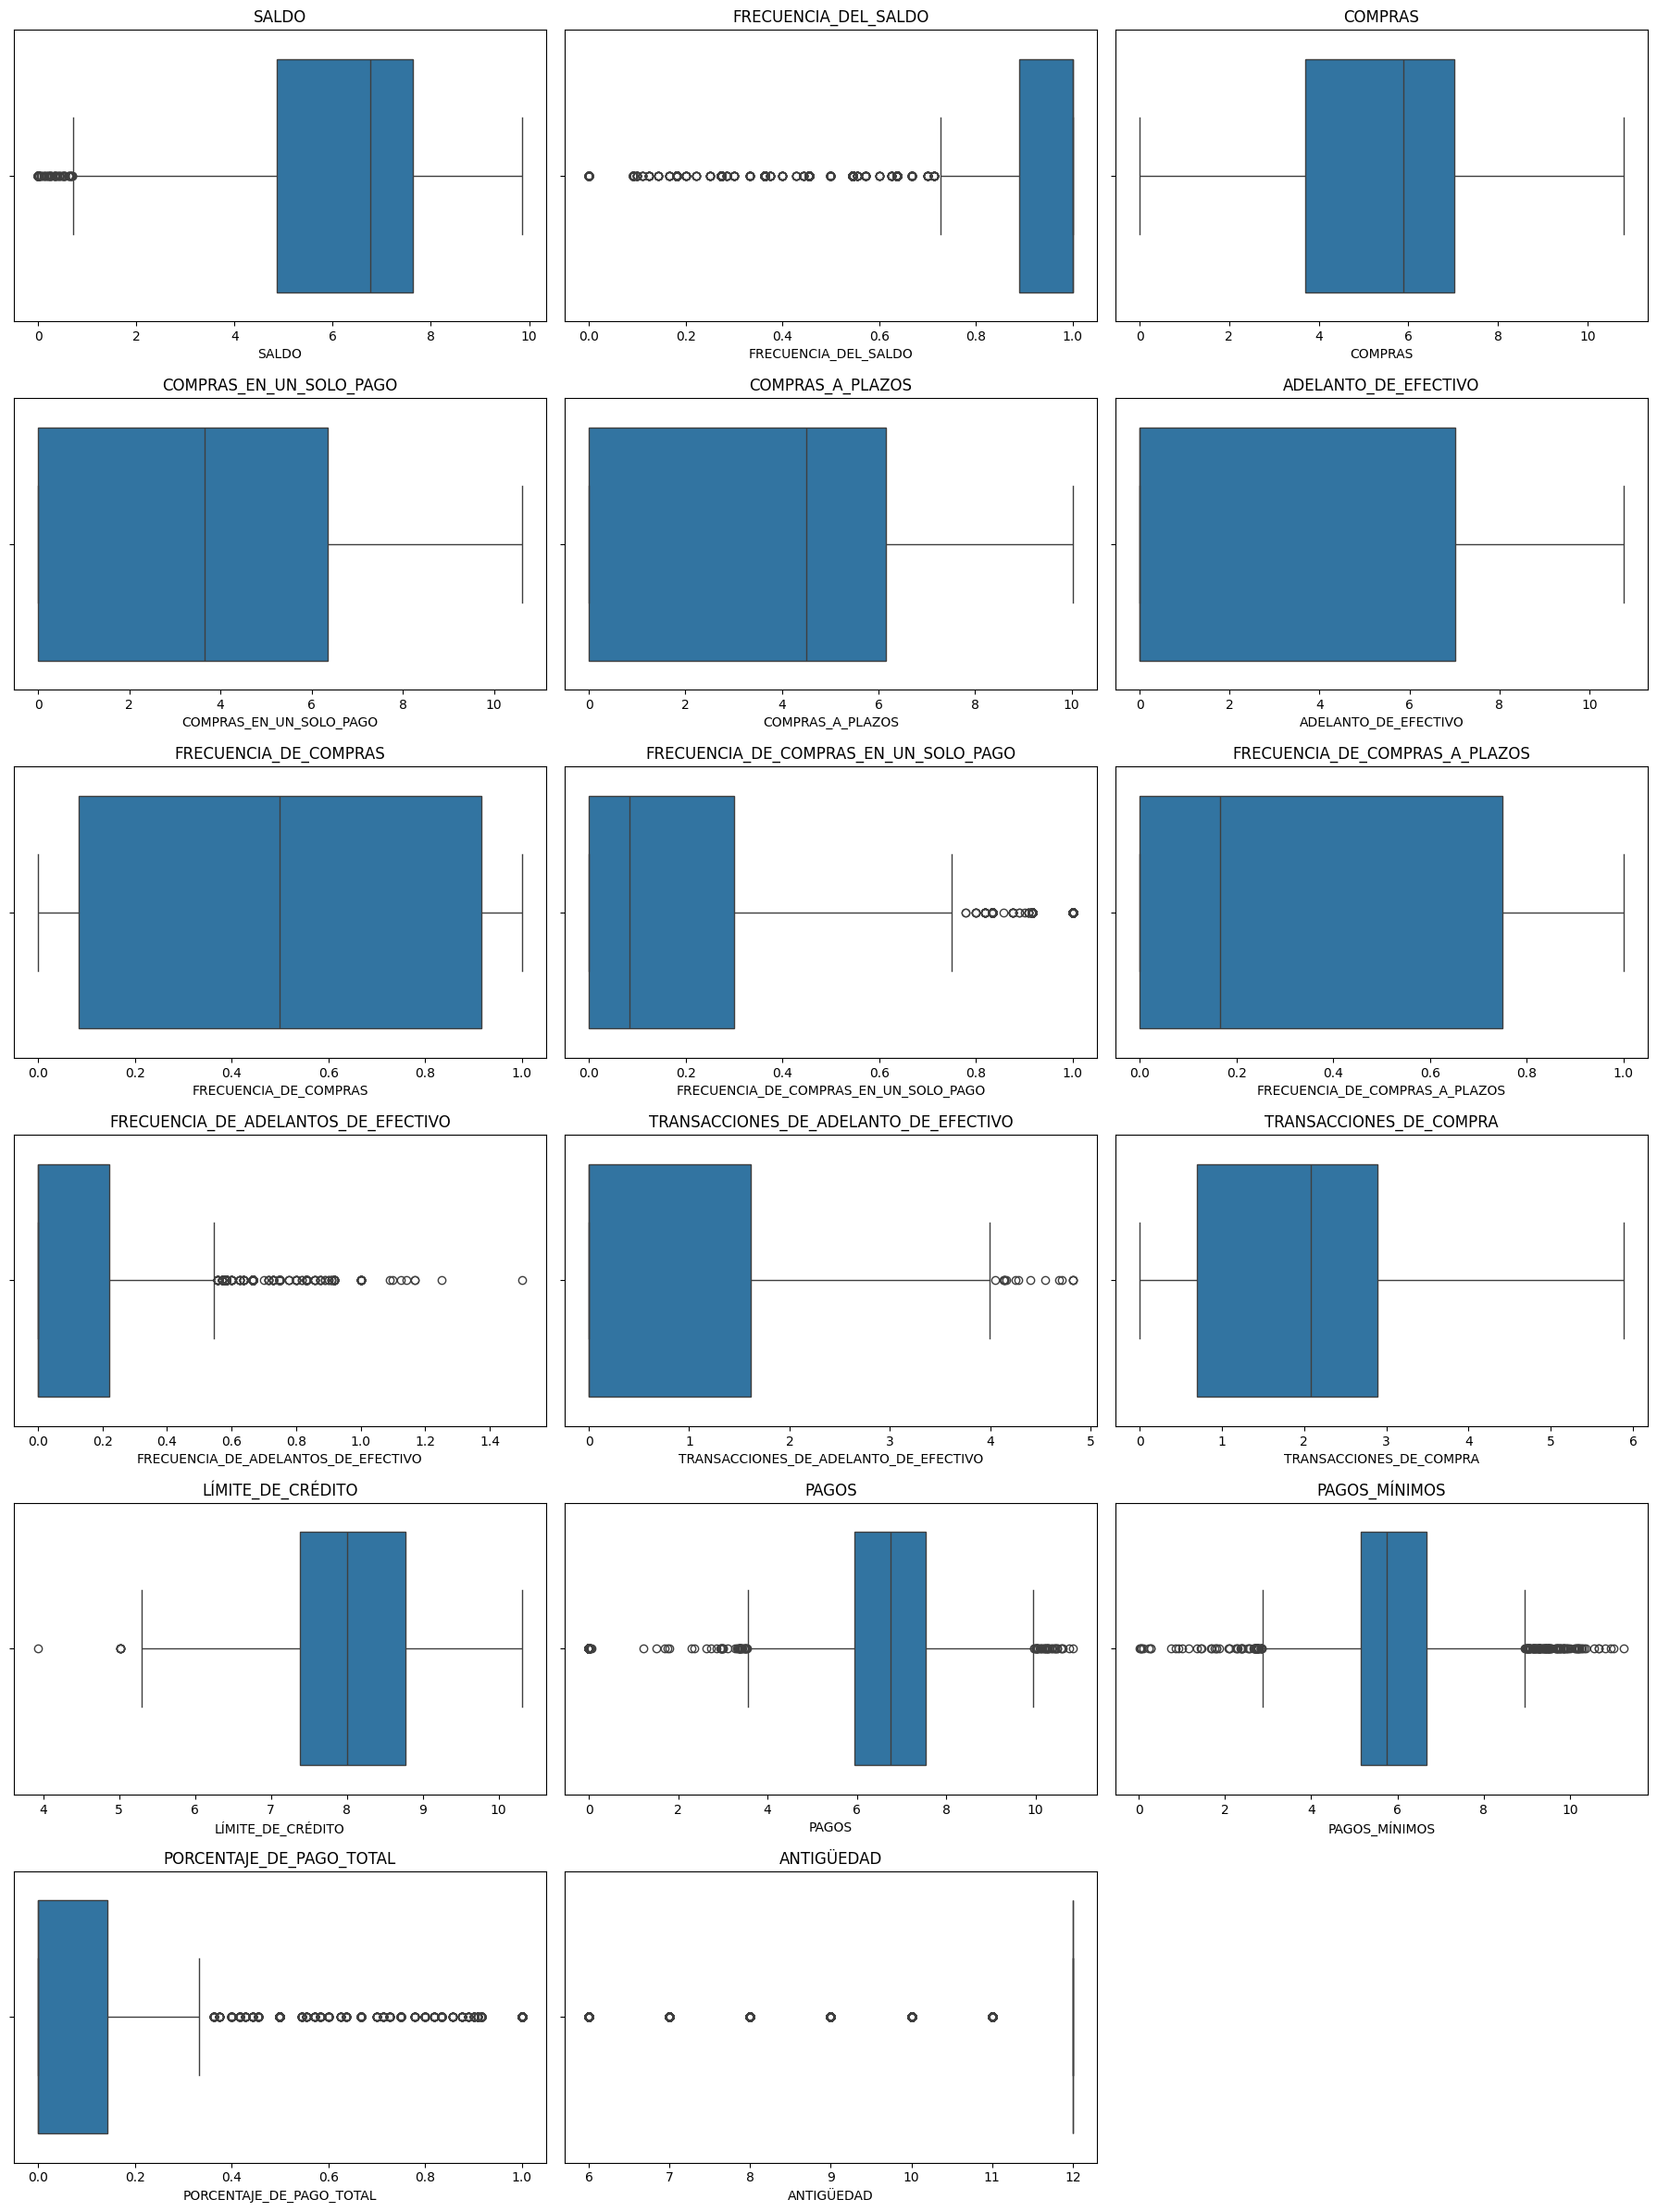

In [ ]:
# Visualización tras la transformación logarítmica
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df_log, x=col, ax=axes[i])
    axes[i].set_title(col)

for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [ ]:
# escalado de datos
def scale_data(df, id_col="ID_CLTE"):
    feature_cols = (
        df.drop(columns=id_col, errors="ignore").select_dtypes(include="number").columns
    )

    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df[feature_cols])

    scaled_df = pd.DataFrame(scaled_data, columns=feature_cols, index=df.index)

    # Devuelve también el escalador, los datos escalados o las columnas de características, si es necesario.
    return scaled_df

df_scaled = scale_data(df_log)

## Resumen del preprocesamiento

- `df_imputed`: Valores faltantes imputados; escala original preservada
- `df_log`: Datos transformados logarítmicamente para variables numéricas con sesgo
- `df_scaled`: Datos escalados mediante estandarización para agrupamiento (clustering)

# Clustering

## K-means

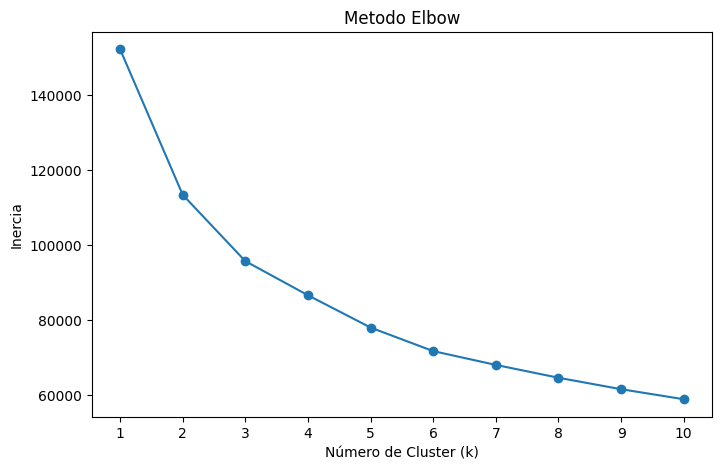

In [ ]:
# Elbow method
inertia_list = []

k_range = range(1,11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia_list.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(k_range, inertia_list, marker='o')
plt.xlabel("Número de Cluster (k)")
plt.ylabel("Inercia")
plt.title("Metodo Elbow")
plt.xticks(k_range)
plt.show()

La curva del codo no muestra un punto de inflexión marcado, pero la reducción de la inercia se vuelve más gradual a partir de k=4.

En este proyecto, seleccionamos k = 4 porque proporciona cluster más interpretables desde una perspectiva empresarial.

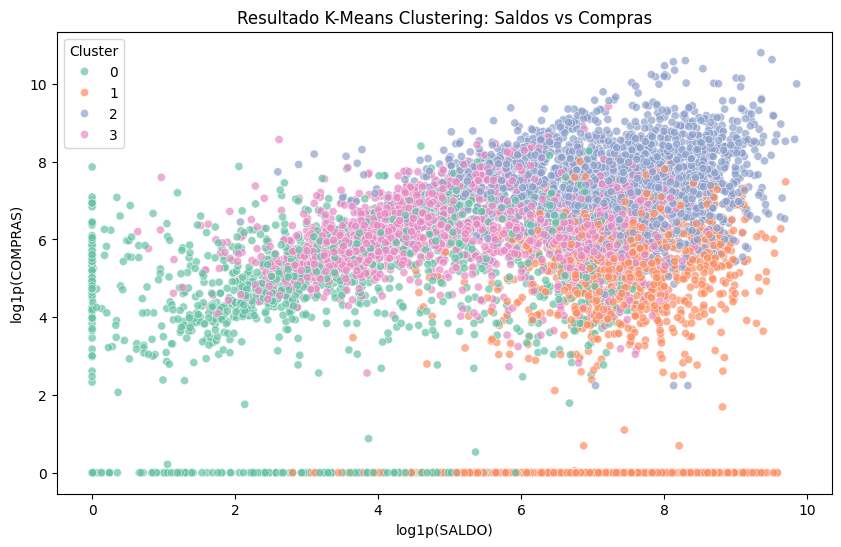

In [ ]:
# kmeans con 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
kmeans.fit(df_scaled)

labels = kmeans.labels_

# añadir etiquetas de clúster al dataframe imputado
df_clusters = df_imputed.copy()
df_clusters["cluster_kmeans"] = labels

# DF temporal para visualización
df_kmeans_plot = df_log.copy()
df_kmeans_plot["cluster_kmeans"] = labels

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_kmeans_plot,
    x="SALDO",
    y="COMPRAS",
    hue="cluster_kmeans",
    palette="Set2",
    alpha=0.7,
    s=35,
)

plt.title("Resultado K-Means Clustering: Saldos vs Compras")
plt.xlabel("log1p(SALDO)")
plt.ylabel("log1p(COMPRAS)")
plt.legend(title="Cluster")
plt.show()


In [ ]:
df_clusters["cluster_kmeans"].value_counts().sort_index()


,count
cluster_kmeans,
0,1570
1,2760
2,2580
3,2040


In [ ]:
# extraer columnas de características
feature_cols = [
    col
    for col in df_clusters.columns
    if col != "ID_CLTE" and not col.startswith("cluster_")
]

# scale data
df_clusters_scaled = scale_data(df_clusters[feature_cols])


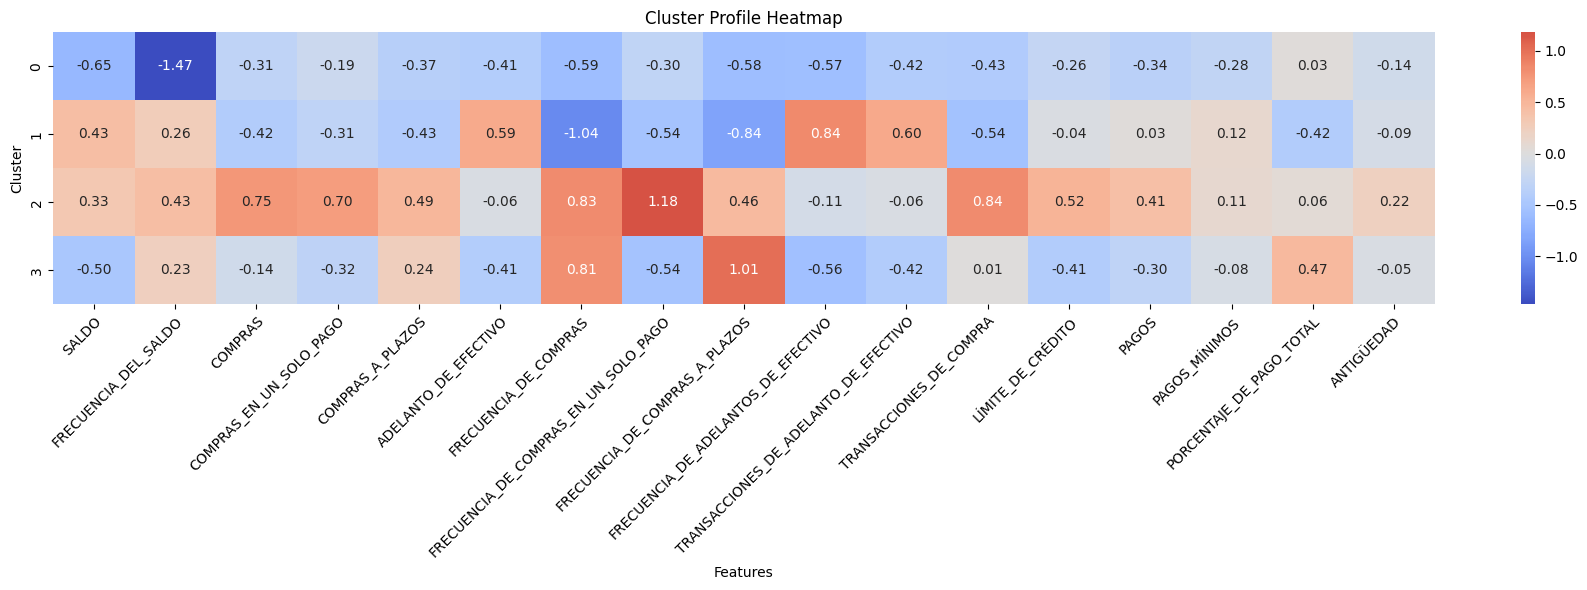

In [ ]:
# DF temporal para la visualización de mapas de calor
df_clusters_scaled_mean = df_clusters_scaled.copy()

# volver a añadir las etiquetas de clúster al dataframe escalado
df_clusters_scaled_mean["cluster_kmeans"] = df_clusters["cluster_kmeans"].values

# calcular los valores medios por clúster para la visualización en mapa de calor
df_clusters_scaled_mean = df_clusters_scaled_mean.groupby("cluster_kmeans")[
    feature_cols
].mean()

fig, ax = plt.subplots(figsize=(18, 6))

sns.heatmap(
    df_clusters_scaled_mean, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax
)

ax.set_title("Cluster Profile Heatmap")
ax.set_xlabel("Features")
ax.set_ylabel("Cluster")

ax.set_xticklabels(
    ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"
)

plt.tight_layout()
plt.show()


## PCA + K-means

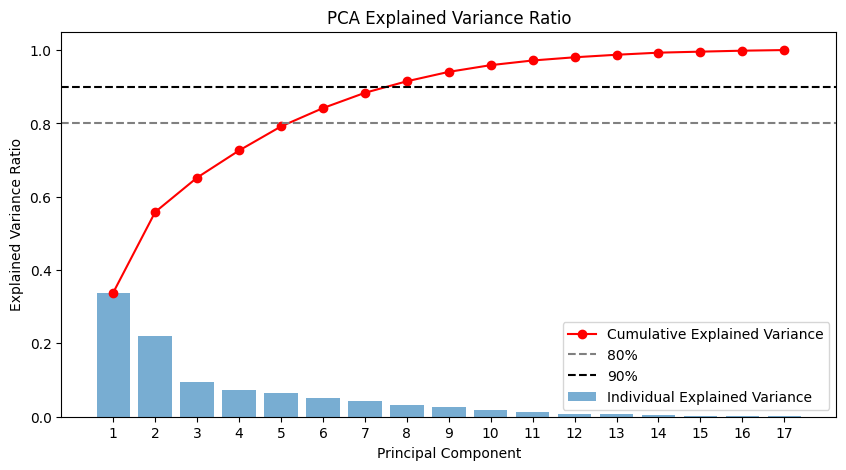

In [ ]:
pca = PCA()
pca.fit(df_scaled)

explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)
components = range(1, len(explained_variance_ratio) + 1)

plt.figure(figsize=(10, 5))

plt.bar(
    components,
    explained_variance_ratio,
    alpha=0.6,
    label="Individual Explained Variance",
)

plt.plot(
    components,
    cumulative_variance_ratio,
    marker="o",
    color="red",
    label="Cumulative Explained Variance",
)

plt.axhline(y=0.8, color="gray", linestyle="--", label="80%")
plt.axhline(y=0.9, color="black", linestyle="--", label="90%")

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance Ratio")
plt.xticks(components)
plt.legend()
plt.show()


El resultado del PCA muestra que los cinco primeros componentes principales explican cerca del 80 % de la varianza total, mientras que los ocho primeros explican alrededor del 90 %. En este proyecto, se seleccionaron cinco componentes para reducir la dimensionalidad conservando la mayor parte de la información.

In [ ]:
# PCA + K-means
# make df for k-means
pca = PCA(n_components=5)
pca_clusters = pca.fit_transform(df_scaled)

pca_clusters_df = pd.DataFrame(
    pca_clusters,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
    index=df_scaled.index,
)


In [ ]:
pca_clusters_df.columns

Index(['PC1', 'PC2', 'PC3', 'PC4', 'PC5'], dtype='object')

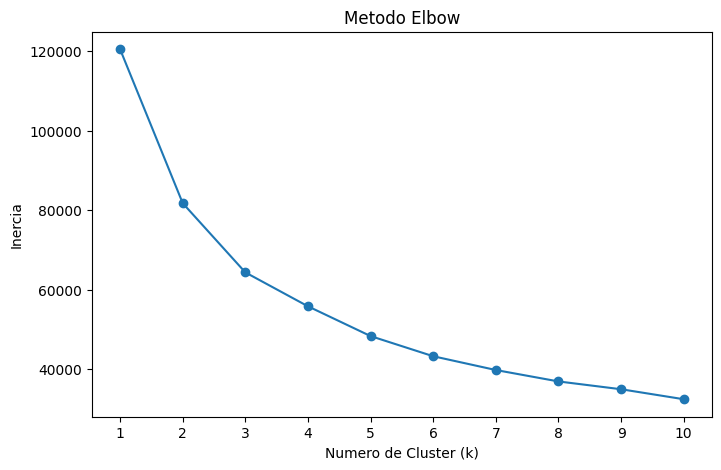

In [ ]:
# Metodo Elbow
inertia_list = []

k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(pca_clusters_df)
    inertia_list.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia_list, marker="o")
plt.xlabel("Numero de Cluster (k)")
plt.ylabel("Inercia")
plt.title("Metodo Elbow")
plt.xticks(k_range)
plt.show()


Tras aplicar PCA con 5 componentes, la curva del codo sigue sugiriendo k = 4 como un número razonable de clústeres. Esto indica que la reducción de dimensionalidad preservó la estructura de agrupamiento principal del espacio de características original.

In [ ]:
# PCA + K-means
pca_feature_cols = [
    "PC1",
    "PC2",
    "PC3",
    "PC4",
    "PC5",
]

pca_feature_df = pca_clusters_df[pca_feature_cols].copy()

kmeans_pca = KMeans(n_clusters=4, random_state=42, n_init=10)
pca_labels = kmeans_pca.fit_predict(pca_feature_df)

pca_clusters_labeled_df = pca_feature_df.copy()
pca_clusters_labeled_df["cluster_kmeans_pca"] = pca_labels

fig = px.scatter_3d(
    pca_clusters_labeled_df,
    x="PC1",
    y="PC2",
    z="PC3",
    color="cluster_kmeans_pca",
    opacity=0.65,
    title="PCA + K-Means Clustering Result (3D)",
)

fig.update_traces(marker=dict(size=3))

fig.update_layout(
    scene=dict(
        xaxis_title=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})",
        yaxis_title=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})",
        zaxis_title=f"PC3 ({pca.explained_variance_ratio_[2]:.1%})",
    ),
    legend_title_text="Cluster",
    width=900,
    height=700,
)

fig.show()

In [ ]:
# Añadir el PCA y la etiqueta de clúster al DataFrame original de k-means.
df_clusters_pca = df_imputed.copy()
df_clusters_pca["cluster_kmeans_pca"] = pca_labels

In [ ]:
df_clusters_pca_scaled = scale_data(df_clusters_pca[feature_cols])
df_clusters_pca_scaled["cluster_kmeans_pca"] = df_clusters_pca[
    "cluster_kmeans_pca"
].values

cluster_profile_pca_scaled = df_clusters_pca_scaled.groupby("cluster_kmeans_pca")[
    feature_cols
].mean()


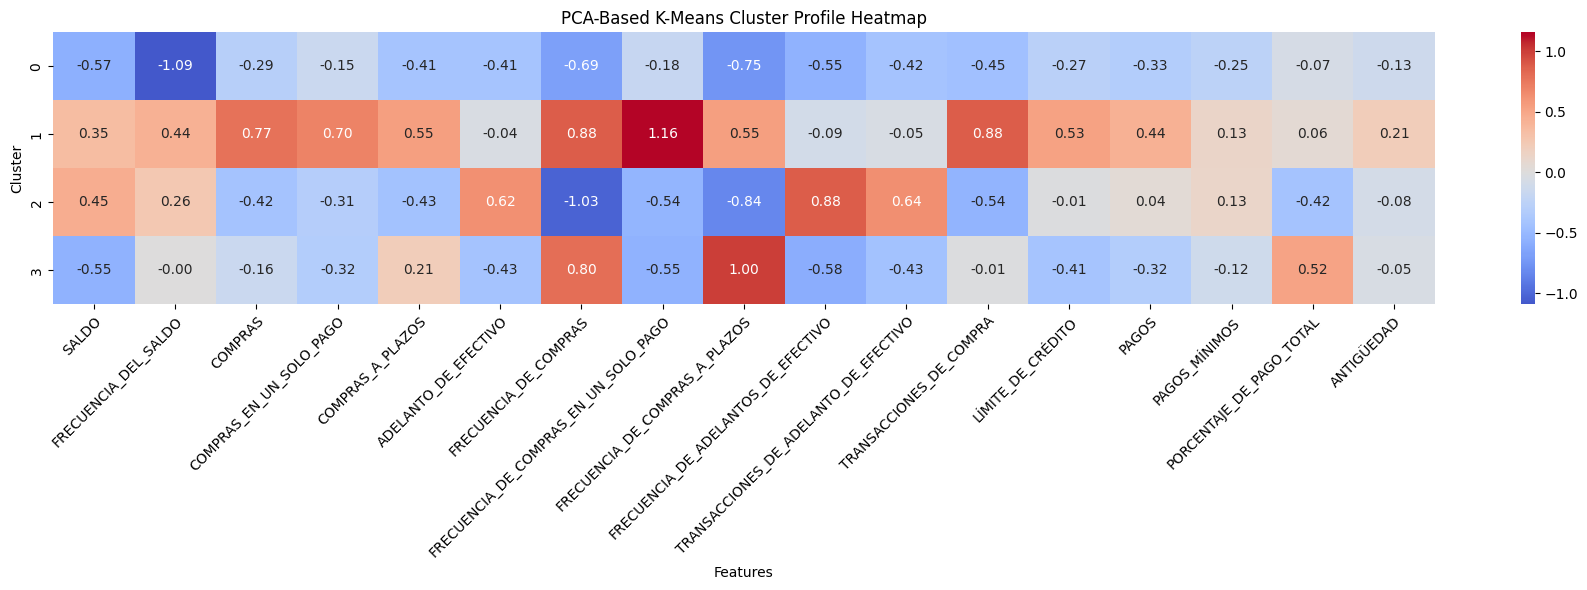

In [ ]:
fig, ax = plt.subplots(figsize=(18, 6))

sns.heatmap(
    cluster_profile_pca_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    ax=ax,
)

ax.set_title("PCA-Based K-Means Cluster Profile Heatmap")
ax.set_xlabel("Features")
ax.set_ylabel("Cluster")

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    rotation_mode="anchor",
)

plt.tight_layout()
plt.show()


### Interpretación de los perfiles del mapa de calor

Al comparar el **mapa de calor de K-Means original** con el **mapa de calor de K-Means basado en PCA**:

1.  **Consistencia en los perfiles**: Las características fundamentales de los clusters permanecen notablemente estables.
    *   El **Cluster 1**, en ambos modelos, representa el segmento de alta actividad y alto volumen de compras.
    *   El **Cluster 2** identifica sistemáticamente al grupo orientado al uso de adelantos de efectivo.
2.  **Reducción de ruido**: El mapa de calor basado en PCA suele mostrar colores «extremos» algo más marcados (azules o rojos más intensos). Esto probablemente se deba a que el PCA filtró la varianza que no contribuía a la estructura principal, haciendo que los valores promedio de las características de cada conglomerado sean más representativos de sus rasgos distintivos.
3.  **Intercambio o desplazamiento de cluster**: Aunque el índice ARI es elevado (0,85), se produce cierta reasignación en los límites. El PCA tiende a agrupar o separar puntos basándose en la varianza global en lugar de en el ruido local de características específicas —como *ANTIGÜEDAD* o *PORCENTAJE_DE_PAGO_TOTAL*— si estas no se alinean con los componentes principales.


In [ ]:
df_clusters_pca["cluster_kmeans_pca"].value_counts().sort_index()


,count
cluster_kmeans_pca,
0,1642
1,2515
2,2692
3,2101


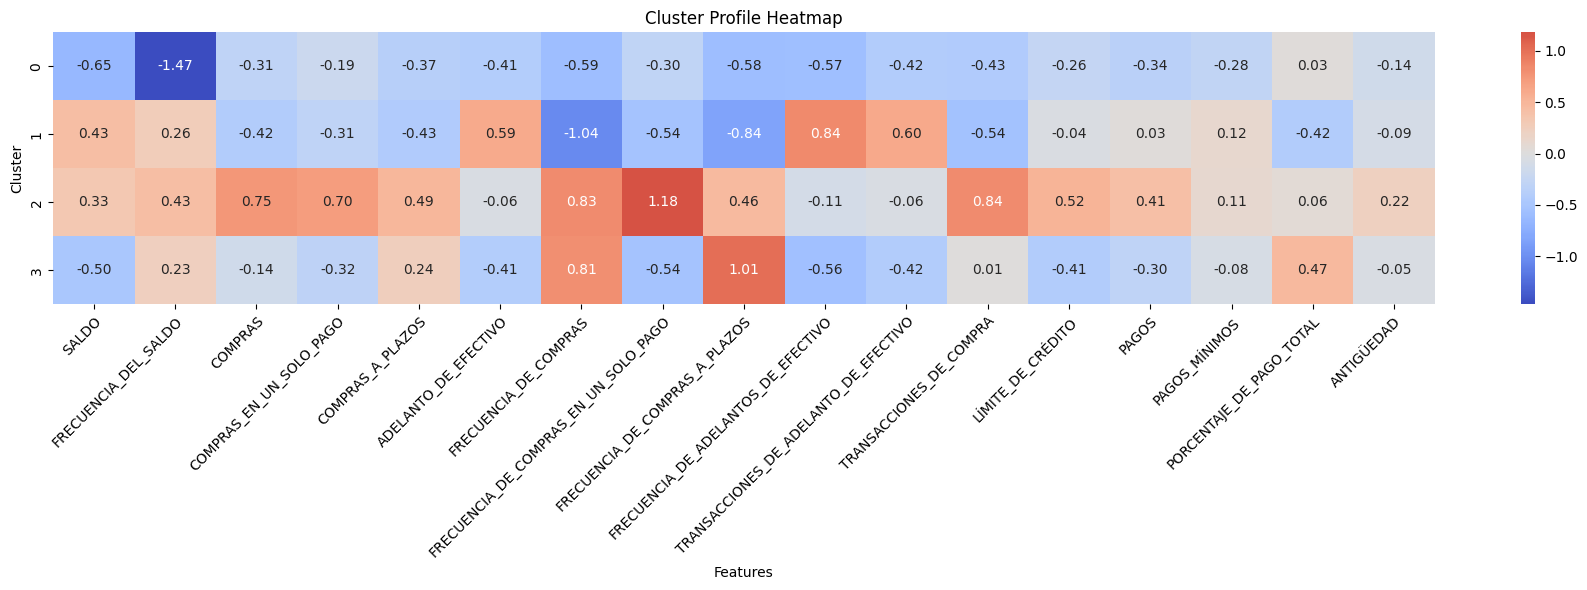

In [ ]:
# original K-means for comparison
fig, ax = plt.subplots(figsize=(18, 6))

sns.heatmap(
    df_clusters_scaled_mean, annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax
)

ax.set_title("Cluster Profile Heatmap")
ax.set_xlabel("Features")
ax.set_ylabel("Cluster")

ax.set_xticklabels(
    ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor"
)

plt.tight_layout()
plt.show()


In [ ]:
df_clusters["cluster_kmeans"].value_counts().sort_index()


,count
cluster_kmeans,
0,1570
1,2760
2,2580
3,2040


# Comparación

In [ ]:
adjusted_rand_score(
    df_clusters["cluster_kmeans"], df_clusters_pca["cluster_kmeans_pca"]
)


0.8546490080746622

El resultado de KMeans basado en PCA mostró un elevado Índice de Rand Ajustado (ARI = 0,855) en comparación con el resultado de KMeans utilizando todas las características, lo que indica que la estructura principal de segmentación se preservó en gran medida tras la reducción de dimensionalidad.

In [ ]:
silhouette_full = silhouette_score(df_scaled, df_clusters["cluster_kmeans"])
silhouette_pca = silhouette_score(
    pca_clusters_df, df_clusters_pca["cluster_kmeans_pca"]
)

comparison = pd.DataFrame(
    {
        "Model": ["Full Feature KMeans", "PCA-Based KMeans"],
        "Silhouette Score": [silhouette_full, silhouette_pca],
    }
)

comparison


,Model,Silhouette Score
0,Full Feature KMeans,0.216579
1,PCA-Based KMeans,0.272705


### Métricas Detalladas de Cohesión y Separación

Analizaremos la calidad de los clústeres mediante el coeficiente de silueta individual para evaluar si existen solapamientos significativos o muestras mal clasificadas.

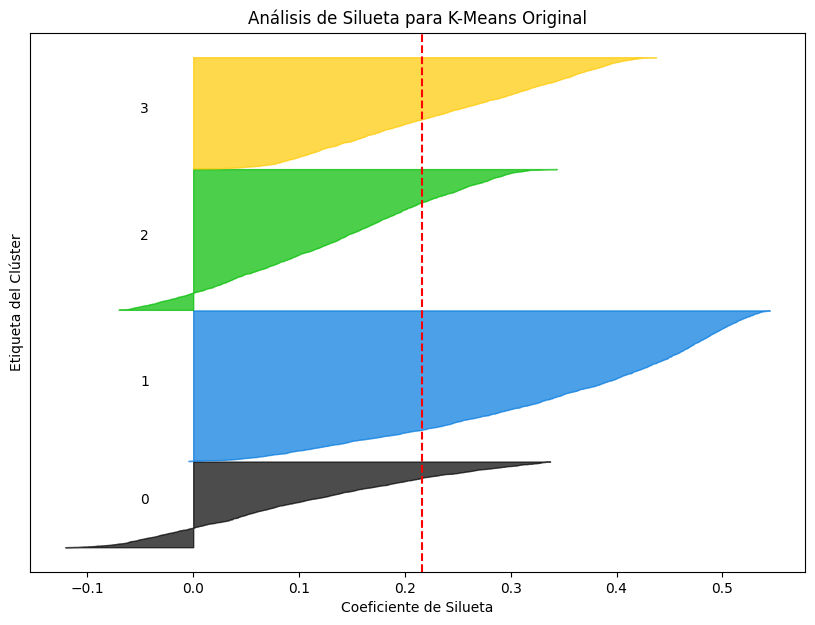

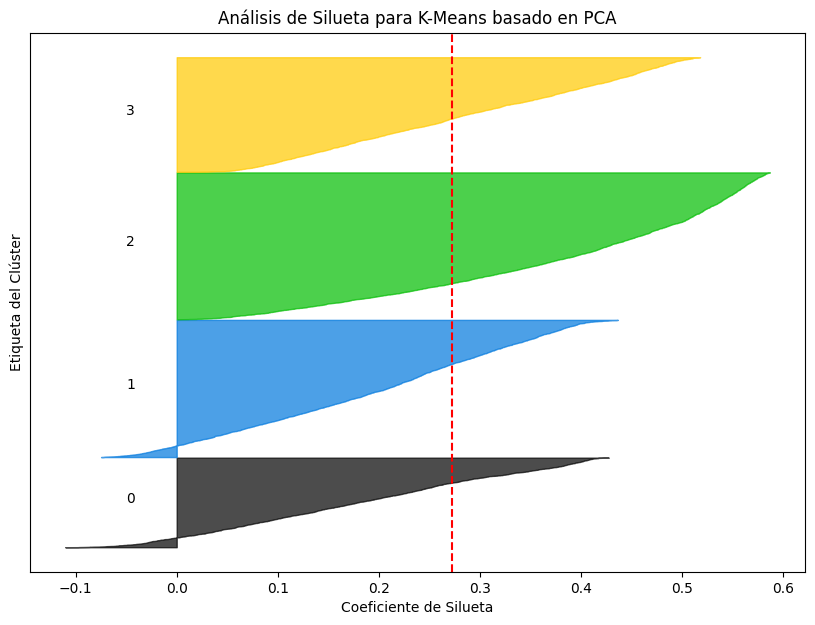

In [ ]:
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

def plot_silhouette(X, cluster_labels, title):
    n_clusters = len(np.unique(cluster_labels))
    fig, ax = plt.subplots(figsize=(10, 7))

    # Calcular los valores de silueta para cada muestra
    sample_silhouette_values = silhouette_samples(X, cluster_labels)
    y_lower = 10

    for i in range(n_clusters):
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        y_lower = y_upper + 10

    ax.set_title(f"Análisis de Silueta para {title}")
    ax.set_xlabel("Coeficiente de Silueta")
    ax.set_ylabel("Etiqueta del Clúster")

    # La línea vertical indica el promedio del score
    avg_score = silhouette_score(X, cluster_labels)
    ax.axvline(x=avg_score, color="red", linestyle="--")
    ax.set_yticks([])
    plt.show()

# Visualizar para ambos modelos
plot_silhouette(df_scaled, labels, "K-Means Original")
plot_silhouette(pca_clusters_df, pca_labels, "K-Means basado en PCA")

Aunque ambos coeficientes de Silhouette Score fueron relativamente bajos, el modelo KMeans basado en PCA obtuvo un valor superior (0,273) al del modelo KMeans con el conjunto completo de características (0,217). Esto sugiere que el PCA mejoró ligeramente la separación de los clústeres al reducir el ruido y la información redundante.

# Perspectivas empresariales

A partir del perfil del clúster, los cuatro grupos de clientes pueden interpretarse de la siguiente manera.

- **Cluster 0: Clientes de baja actividad**  
  Este grupo presenta una actividad relativamente baja en la mayoría de las variables, incluyendo el importe de compra, la frecuencia de compra, el límite de crédito y el importe de los pagos. Estos clientes no parecen utilizar activamente sus tarjetas de crédito. Podrían resultar adecuadas las campañas de activación básicas, como pequeñas ofertas de reembolso (*cashback*) o incentivos por la primera compra.

- **Cluster 1: Clientes clave de alta actividad**  
  Este grupo presenta una elevada actividad de compra, transacciones frecuentes, importes de pago elevados y límites de crédito relativamente altos. Estos clientes pueden considerarse el grupo objetivo principal para las campañas de marketing. Los programas de recompensa, los beneficios exclusivos, las promociones personalizadas o las ofertas de ampliación del límite de crédito pueden resultar eficaces.

- **Cluster 2: Clientes de riesgo con tendencia al uso de adelantos de efectivo**  
  Este grupo presenta un uso relativamente elevado de adelantos de efectivo y una baja tasa de pago total del saldo. Si bien pueden tener necesidades de productos financieros, también requieren una gestión de riesgos cuidadosa. En lugar de una expansión agresiva del crédito, podrían resultar más adecuadas las alternativas a los adelantos de efectivo, los planes de pago a plazos o las ofertas financieras conservadoras.

- **Cluster 3: Clientes con compras planificadas y estables**  
  Este grupo muestra un comportamiento de compra a plazos relativamente más marcado y una tendencia al pago total del saldo, mientras que el uso de adelantos de efectivo es bajo. Es probable que estos clientes utilicen las tarjetas de crédito de manera más planificada y estable. Las promociones de pago a plazos, los beneficios en comercios asociados y las campañas de compras planificadas podrían resultar adecuados para este segmento.

Las estrategias de marketing recomendadas para cada grupo son las siguientes.

- **Cluster 0:** Incentivos para la primera compra, pequeñas ofertas de reembolso (*cashback*) y campañas de reactivación para prevenir la inactividad del cliente.
- **Cluster 1:** Programas de recompensas, beneficios *premium*, ofertas de aumento del límite de crédito y campañas de marketing VIP.
- **Cluster 2:** Productos alternativos de adelanto de efectivo, planes de pago a plazos y un seguimiento riguroso del riesgo.
- **Cluster 3:** Promociones de pago a plazos sin intereses, beneficios en comercios asociados y campañas de financiación para compras relacionadas con el estilo de vida, electrónica, electrodomésticos o viajes.